<img src='./img/up_bann.png' style="display: block; margin: 0 auto;">

# Detecting forest clearing with Sentinel-1 coherence 🌳 🛰️

## Challenge #1 @ 12th CASSINI  Hackathon: Cybersecurity for space-based strategic enablers (Change detection)

Can satellite radar show when a forest has been cleared, even under cloud? In this notebook you will use the APEx Sentinel-1 Coherence algorithm to compare two periods over a forested area near Petrozavodsk, Russia, and map where the ground has changed.

This notebook takes the single-date workflow from [APEx 101](./apex_101.ipynb) and runs it over two periods of interest for change detection.


According to a [report by Ukrainian National News (UNN)](https://unn.ua/en/news/russia-massively-cuts-down-forests-near-finland-to-build-military-bases-cpd), large-scale tree clearing was reported to have taken place in border areas of north-west Russia, near Finland.<br>

Sentinel-1 is a radar satellite. It records images day and night, whatever the weather, so it can detect change when optical satellites are blocked by cloud. One common use is change detection, such as the loss of vegetation.

Based on the [UNN post](https://unn.ua/en/news/russia-massively-cuts-down-forests-near-finland-to-build-military-bases-cpd) report, the clearing took place between June and July 2026. This notebook does not verify the report. It shows how Sentinel-1 can be used to look for that kind of change.


By the end of this notebook, you will be able to...

- Search the CDSE Sentinel-1 burst catalogue for a place and a time window
- Access the burst description and run the [APEx Sentinel-1 Coherence algorithm](https://algorithm-catalogue.apex.esa.int/apps/sentinel1_sar_coherence) on the [CDSE openEO](https://dataspace.copernicus.eu/analyse/openeo) federation.
- Visualise the change before and after forest clearing.
- Create a coherence change (Δγ) map

### **Prerequisites:**

#### 🛠️ Dependencies 
As we will be working with the APEx algorithms, it is important to install the following dependencies in your desired environment:

```text
- git
- git+https://github.com/ESA-APEx/apex_algorithms.git # The up-to-date version of apex_algorithms
- openeo
```
You can make use of the `environment.yml` available in this repository to run all the notebooks!

#### 🛰️ openEO 

It is also good, to have an understanding of [openEO UDPs](https://open-eo.github.io/openeo-python-client/udp.html), as the APEx algorithms are based on them. You can find examples that explain how to use the `openeo` library in their [Python Client Examples](https://github.com/Open-EO/openeo-community-examples/tree/main/python).

#### 🔐 Github Authentication 

The `esa_apex_toolbox` library makes use of **Repository access** wich reads remote GitHub content, not local catalogue changes!<br>

If your environment defines `GITHUB_TOKEN`, the token cell below picks it up. Otherwise you will be asked for one, and you can press Enter to continue without it.

With the packages installed, we can start. 🚀 🛰️

### Import Required libraries

In [1]:
%matplotlib inline

import io
from getpass import getpass
import os
from pathlib import Path
import urllib.request
import site 

from esa_apex_toolbox.algorithms import GithubAlgorithmRepository
import geopandas as gpd
import openeo
import xarray as xr

import folium
import leafmap
from shapely.geometry import box
import matplotlib.image as mpimg
import matplotlib.pyplot as plt


### Define Access to the CDSE Burst Catalogue

The following parameters, help setting up the retrieval of the `burst_id` parameter used in the Sentinel-1 coherence algorithm. Check out the **InSAR Workflow Input Selection** tutorial [here](https://github.com/cloudinsar/s1-workflows/blob/main/input_selection/InSAR_workflow_input_selection.ipynb)

We will patch some imports as we only want to retrieve metadata. If the upstream file changes, the patch should change.

In [2]:
lib_path = os.path.join(site.getsitepackages()[0], "s1_burst_lib.py")
if not os.path.exists(lib_path):
    code = urllib.request.urlopen("https://raw.githubusercontent.com/cloudinsar/s1-workflows/refs/heads/main/input_selection/s1_burst_lib.py").read().decode()
    with open(lib_path, "w") as f:
        f.write(code.replace("import esa_snappy as snappy", "# import esa_snappy as snappy"))

import s1_burst_lib

from s1_burst_lib import retrieve_bursts, show_acquisition_calendar, show_bursts

We start by bringing in our github credentials and set the token to access our APEx Catalog.


In [3]:
github_token = os.environ.get('GITHUB_TOKEN') or os.environ.get('GH_TOKEN')
if not github_token:
    github_token = getpass('GitHub token (optional; Enter for unauthenticated access): ') or None

> ##### Remember
> Always **treat a token as a password**: never print it, put it in a committed file, or include it in notebook outputs. Revoke and replace it immediately if exposed; replace it when it expires. Authentication is applied to GitHub API directory requests, not raw catalogue or process-definition downloads.


## 1️⃣ Accessing the algorithm

We connect to the catalogue and ask for the algorithm by its id. According to the [APEx Catalogue](https://algorithm-catalogue.apex.esa.int/?q=Sentinel-1+Co) the id for **Sentinel-1 Coherence** is `sentinel1_sar_coherence`.

In [4]:
repo = GithubAlgorithmRepository(
    owner='ESA-APEx',
    repo='apex_algorithms',
    folder='algorithm_catalog',
    branch='main',
    token=github_token,
)

s1c_algorithm = repo.get_algorithm('sentinel1_sar_coherence')
s1c_algorithm

Algorithm(id='sentinel1_sar_coherence', title='Sentinel-1 Coherence', description='This process generates a time series of Sentinel‑1 interferometric coherence for a set of interferometric pairs. The area of interest is specified at burst level using the Sentinel‑1 burst_id and sub_swath, ensuring precise spatial targeting and consistent acquisition geometry across the time series.\nInterferometric pairs are automatically defined by specifying a temporal extent and temporal baseline.\nThe workflow is implemented using ESA SNAP operators and is defined as a Common Workflow Language (CWL) pipeline [sar_coherence.cwl](https://github.com/cloudinsar/s1-workflows/blob/main/cwl/sar_coherence.cwl).\nInterferometric coherence provides a quantitative measure of phase stability between acquisitions and is widely used to assess surface change and temporal decorrelation driven by factors such as snow cover, vegetation dynamics, surface moisture, or mass movement. Coherence time series can be used for a variety of scientific and operational applications, including land cover classification, change detection, and as a diagnostic input for more advanced SAR analysis workflows.\n\nAn example on how to use it:\n\n```python\nimport openeo\n\nconnection = openeo.connect("https://openeo.dataspace.copernicus.eu").authenticate_oidc()\nstac_resource = connection.datacube_from_process(\n    "sentinel1_sar_coherence",\n    namespace="https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/refs/heads/main/algorithm_catalog/eurac/sentinel1_sar_coherence/openeo_udp/sentinel1_sar_coherence.json",\n    **{\n        "temporal_extent": ["2018-01-28", "2018-02-04"],\n        "temporal_baseline": 6,\n        "burst_id": 329488,\n        "coherence_window_az": 2,\n        "coherence_window_rg": 10,\n        "polarization": "VH",\n        "sub_swath": "IW2"\n    }\n)\n\njob = stac_resource.create_job(title="sentinel1_sar_coherence test")\njob.start_and_wait()\njob.get_results().download_files()\n```', udp_link=UdpLink(href='https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/main/algorithm_catalog/eurac/sentinel1_sar_coherence/openeo_udp/sentinel1_sar_coherence.json', title='openEO Process Definition'), service_links=[ServiceLink(href='https://openeofed.dataspace.copernicus.eu', title='CDSE openEO federation')], license=None, organization=None, provider='VITO', platforms=['CDSE'], keywords=['Sentinel-1', 'Radar'])

Printing the algorithm shows its **title**, **id**, and **related metadata**. We are interested in the parameter `udp_link`, as it will give us access to the **UDP**.
<br>

The algorithm’s `udp_link` points to the openEO process we will run within the APEx Catalogue. We take its `href` (the web address), and use it to build the job.

In [5]:
s1c_link = s1c_algorithm.udp_link.href
s1c_link

'https://raw.githubusercontent.com/ESA-APEx/apex_algorithms/main/algorithm_catalog/eurac/sentinel1_sar_coherence/openeo_udp/sentinel1_sar_coherence.json'

## 2️⃣ Defining the area and time frame of interest: Petrozavodsk

Petrozavodsk is a city on the western shore of Lake Onega, in northwest Russia. According to [the UNN article](https://unn.ua/en/news/russia-massively-cuts-down-forests-near-finland-to-build-military-bases-cpd), the clearance of the forested area, seems to be related to military activity.<br>

We define our bounding box to the area of interest:

In [6]:
geometry = [34.380255,61.740142,34.432955,61.758424]  # west, south, east, north
shape = {'west': geometry[0], 'south': geometry[1], 'east': geometry[2], 'north': geometry[3]}
aoi_wkb = box(*geometry).wkt

# to visualise our aoi
aoi = gpd.GeoSeries(box(*geometry), crs='EPSG:4326')
aoi.explore(color='red')

### Filtering interest dates

We will search for Sentinel-1 busrsts that cover the fowllowing periods

| Step / Phase | Target Date Window | Rationale & Expected Radar Behavior |
| :--- | :--- | :--- |
| **Before** | May - June 2026 | Full canopy (visualised through Sentinel-2 imagery) |
| **After** | August - September 2026 | Bare soil (visualised through Sentinel-2 imagery) |


In [7]:
dates_ranges = [["2026-05-15","2026-06-05"],
              ["2026-08-15","2026-09-30"]]

## 3️⃣ CDSE burst catalogue query

Then, following the [**InSAR Workflow Input Selection** tutorial](https://github.com/cloudinsar/s1-workflows/blob/main/input_selection/InSAR_workflow_input_selection.ipynb), we retrieve the burst information based on:

- Dates of interest (our `dates_ranges`)
- Polarisation we are interested in (use VV for surfaces, water, soil, and urban double-bounce; VH for vegetation structure and volume scattering)
- The AOI as WKT (well-known text)

> ##### What is a burst?
> A **track** is the ground path the satellite follows. Passes along the same track see the same area from the same angle, so their images can be compared.<br>
> **Sentinel-1 does not record one continuous image**. It scans the ground in three side-by-side strips called sub-swaths (IW1, IW2 and IW3). Each strip is recorded as a series of short segments called bursts. Every burst has a unique burst_id, and the same burst is captured again on each pass along its track.<br>
> **Coherence** can only be computed between bursts that match exactly. That is why we look for one burst that covers the whole area, and keep its sub-swath and burst_id fixed for both periods.


The `retrieve_bursts` function function sends an HTTPS request to the CDSE OData API and returns the bursts that match these inputs. This tells us which bursts cover our area, and which dates exist for the baseline we will use.

In [8]:
# We define the polarization to detect vegetation change
pol = "VH"

# we retrieve the bursts available covering our AOI
s1_bursts_before = retrieve_bursts(dates_ranges[0][0], dates_ranges[0][1], pol, aoi_wkb)
s1_bursts_after = retrieve_bursts(dates_ranges[1][0], dates_ranges[1][1], pol, aoi_wkb)

###  Visualise the available bursts 👀🛰️

Once retrieved, we can access and explore the location for the available bursts.

In both periods, the maps show two bursts that cover the whole area. The area of interest is drawn on each map. Hover over a burst to read its sub-swath and burst_id. We choose one of the two bursts to run the [Sentinel-1 Coherence Algorithm](https://algorithm-catalogue.apex.esa.int/apps/sentinel1_sar_coherence).

We will inspect which id belongs to them:

In [9]:
tracks1, m1 = show_bursts(s1_bursts_before, aoi_wkb)
m1

In [10]:
tracks2, m2 = show_bursts(s1_bursts_after, aoi_wkb)
m2

### Pre and Post Acquisition Calendar 🗓️

To understand the result of our data query for Sentinel-1, `show_acquisition_calendar` funciton, allows us to visualise a calendar showing on which date the corresponding track has been acquired.

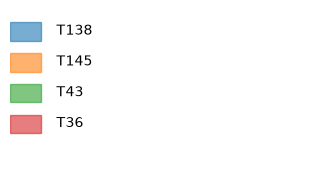

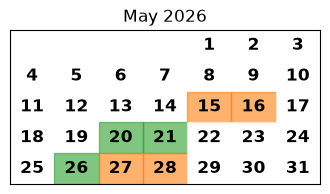

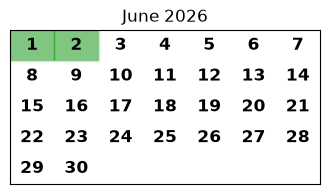

In [11]:
show_acquisition_calendar(s1_bursts_before)

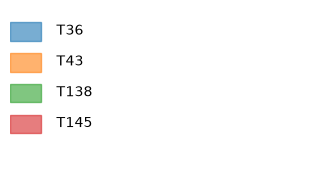

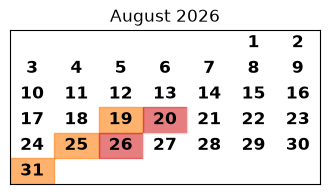

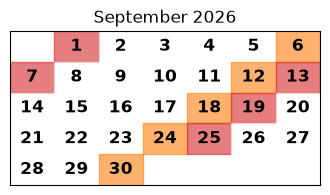

In [12]:
show_acquisition_calendar(s1_bursts_after)

According to the APEx Catalogue, our algorithm needs the definition of a **Temporal Baseline**:

*The temporal baseline should be a multiple of 6. This is used to select how many days the secondary date will be after the primary for each date pair.*

> ##### What is the temporal baseline?
> The coherence algorithm compares pairs of radar images. The **temporal baseline** is the time between the two images in each pair.<br>
> The baseline is a trade-off. Over a short gap, vegetation and soil have little time to change, so coherence stays high. Over a longer gap, the canopy moves more between passes, and coherence drops.

For our algorithm, we will define 12 days, so each coherence value compares an image with the one captured 12 days later on the same track.<br>
A 12-day gap is a practical choice: the catalogue can confirm that it exists for our track, and it keeps enough coherence over stable surfaces to show a change.<br>
The calendar above shows the acquisition dates for each track, so we can check that 12-day pairs are available.

### Choose the track, sub-swath and burst ⏳

Each track lists the bursts it contains, with each burst indented below its track. Look for the same burst ID under both periods. Each burst has a sub-swath (IW1, IW2 or IW3) and a `burst_id`.

We explore both of our timeframes to define the same `BurstId`.

In [13]:
print("Bursts Before:")
for x in tracks1:
  print(x["label"])
  for y in x["children"]:
    print("  " + y["label"]) 

print("Bursts After:")
for x in tracks2:
  print(x["label"])
  for y in x["children"]:
    print("  " + y["label"]) 

Bursts Before:
Track 138
  BurstId: 294972, IW3
Track 145
  BurstId: 309669, IW1
Track 43
  BurstId: 90578, IW3
  BurstId: 90579, IW3
Track 36
  BurstId: 75882, IW2
  BurstId: 75883, IW2
Bursts After:
Track 43
  BurstId: 90578, IW3
  BurstId: 90579, IW3
Track 138
  BurstId: 294972, IW3
Track 36
  BurstId: 75882, IW2
  BurstId: 75883, IW2
Track 145
  BurstId: 309669, IW1


To continue, we will select one of the available `sub_swath_identifier` (e.g. IW1, IW2, IW3) and `burstId` from the list.

We use the burst that covers the whole area in both periods. A burst that covers only part of the area would give coherence values for that part only, so the result would be incomplete.

Coherence can only be computed between matching bursts, so the sub-swath and burst ID must be the same in both periods. If the check in the previous cell fails, choose another burst from the printed lists, and run the check again.

In [14]:
sub_swath_identifier_s1 = "IW1"
burst_id_s1 = 309669

## 4️⃣ Accesing algorithm through CDSE openEO federation

Now we run the Sentinel-1 Coherence algorithm for our two periods. We run one job per period, through the CDSE openEO federation. The workflow has six steps:

1. Connect to the backend
2. Build the Sentinel-1 Coherence process for each time frame and narrow the retrieval to the AOI
3. Run the job
4. Access the resulting time series through xarray
5. Perform the Coherence Mean to obtain a composite
6. Visualise the before; after and delta coherence maps.

The first step is connecting to the CDSE openEO federation backend. The first time you run this cell, a browser window opens for you to log in.

In [15]:
connection = openeo.connect("openeofed.dataspace.copernicus.eu").authenticate_oidc() # connecting

Authenticated using refresh token.


Once connected, we will start our job definition.

For more on openEO processes and the CDSE federation, see the [CDSE openEO documentation](https://openeo.org/documentation/1.0/). [APEx 101](./apex_101.ipynb) explains user-defined processes.

## 5️⃣ Before the clearing

### Defining our job

We take the first period from `dates_ranges` and construct our `datacube_from_process` following the required arguments for [Sentinel-1 Coherence](https://algorithm-catalogue.apex.esa.int/apps/sentinel1_sar_coherence):



In [16]:
before = dates_ranges[0]

sentinel_1_coherence_before = connection.datacube_from_process(
    "sentinel1_sar_coherence", # the process name
    namespace = s1c_link,      # UDP link retrieved from the APEx Catalogue
    temporal_extent = before,  # Starting and Ending date of interest
    temporal_baseline = 12,    # Baseline chosen for our Bursts, 12 days
    burst_id = burst_id_s1,    # Id corresponding for matching Burst
    coherence_window_az = 2,   # the averaging window in azimuth
    coherence_window_rg = 10,  # the averaging window in range
    polarization = pol,        # chosen polarisation
    sub_swath = sub_swath_identifier_s1, # Identifier

).filter_bbox(shape) # cut out only to interest area

We visualise the job though out process graph:

In [17]:
job_before = sentinel_1_coherence_before.create_job(
        title=f'Coherence vis for {before[0]} to {before[1]} VH 12',
        out_format="NetCDF")

job_before

<BatchJob job_id='cdse-j-2611240657144c06af4c98e8bcbf0c82'>

### Running the Job

With the `start_and_wait` function, we will be able to visualise the progress of our job in the CDSE openEO backend.

In [18]:
job_before.start_and_wait() # with this line we run our job and visualise the results 

0:00:00 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': send 'start'
0:00:03 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': created (progress 0%)
0:00:12 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': queued (progress 0%)
0:00:19 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': queued (progress 0%)
0:00:28 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': queued (progress 0%)
0:00:38 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': queued (progress 0%)
0:00:50 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': queued (progress 0%)
0:01:06 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': queued (progress 0%)
0:01:25 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': running (progress N/A)
0:01:49 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': running (progress N/A)
0:02:19 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': running (progress N/A)
0:02:57 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': running (progress N/A)
0:03:43 Job 'cdse-j-2611240657144c06af4c98e8bcbf0c82': running (progress N/A)
0:04:42 J

<BatchJob job_id='cdse-j-2611240657144c06af4c98e8bcbf0c82'>

On our test runs, the job took about from 13-30 minutes. Your time will depend on the queue and your connection.

When the job finishes, we load its result. `get_results` gives us the job's output files, and `get_assets` lists them. We keep the NetCDF file and open it with xarray.

In [19]:
results_before = job_before.get_results()
# get our request
nc_asset_b = next(a for a in results_before.get_assets() if a.key.endswith(".nc"))
asset_url_b = nc_asset_b.href

# we get the Bearer authentication headers from openEO connection
response_b = connection.session.get(asset_url_b)
response_b.raise_for_status()

# stream our netcdf directly into xarray
coherence_before = xr.open_dataset(io.BytesIO(response_b.content), engine="h5netcdf")

coherence_before

<xarray.Dataset> Size: 721kB
Dimensions:  (t: 3, y: 211, x: 283)
Coordinates:
  * t        (t) datetime64[ns] 24B 2026-05-15 2026-05-16 2026-05-21
  * y        (y) float64 2kB 6.848e+06 6.848e+06 ... 6.846e+06 6.846e+06
  * x        (x) float64 2kB 5.729e+05 5.729e+05 ... 5.757e+05 5.757e+05
Data variables:
    crs      |S1 1B ...
    coh_VH   (t, y, x) float32 717kB ...
Attributes:
    Conventions:  CF-1.9
    institution:  Copernicus Data Space Ecosystem openEO API - 0.74.0a6.dev20...
    description:  
    title:

The output shows the dimensions of the data cube: a time dimension `t`, and the spatial dimensions. The variable `coh_VH` holds the coherence values, one layer for each time step in the period.

## 6️⃣ After the clearing

We use the second period, `dates_ranges[1]`, and set the job up in the same way as the before job. Only the period changes, so the two results can be compared.

In [20]:
after = dates_ranges[1]

sentinel_1_coherence_after = connection.datacube_from_process(
    "sentinel1_sar_coherence", # the process name
    namespace = s1c_link,      # UDP link retrieved from the APEx Catalogue
    temporal_extent = after,  # Starting and Ending date of interest
    temporal_baseline = 12,   # Baseline chosen for our Bursts, 12 days
    burst_id = burst_id_s1,   # Id corresponding for matching Burst
    coherence_window_az = 2,  # the averaging window in azimuth
    coherence_window_rg = 10,  # the averaging window in range
    polarization = pol,       # polarization
    sub_swath = sub_swath_identifier_s1, # Identifier

).filter_bbox(shape) # cut out only to interest area

We generate our job

In [21]:
job_after = sentinel_1_coherence_after.create_job(
        title=f'Coherence vis for {after[0]} to {after[1]} VH 12',
        out_format="NetCDF")

job_after

<BatchJob job_id='cdse-j-2611240724184497ac4af7830d90b003'>

### Running the Job

Start the job with `start_and_wait`, which shows its progress. On our test runs, this job took about between 15 and 45 minutes.

In [22]:
job_after.start_and_wait() # with this line we run our job and visualise the results 

0:00:00 Job 'cdse-j-2611240724184497ac4af7830d90b003': send 'start'
0:00:02 Job 'cdse-j-2611240724184497ac4af7830d90b003': created (progress 0%)
0:00:08 Job 'cdse-j-2611240724184497ac4af7830d90b003': queued (progress 0%)
0:00:14 Job 'cdse-j-2611240724184497ac4af7830d90b003': queued (progress 0%)
0:04:02 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:04:12 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:04:26 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:04:41 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:05:01 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:05:25 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:05:55 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:06:32 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0:07:20 Job 'cdse-j-2611240724184497ac4af7830d90b003': running (progress N/A)
0

<BatchJob job_id='cdse-j-2611240724184497ac4af7830d90b003'>

> ##### Remember
> Run times depend on your connection, the backend and the queue. [APEx](https://apex.esa.int/) prepares the algorithm's process in the background. You submit only the parameters you choose, and retrieve the result 🌍✅


Once the job has finished, we load the result with `xarray`

In [23]:
results_after = job_after.get_results()
# get our request
nc_asset_after = next(a for a in results_after.get_assets() if a.key.endswith(".nc"))

# we get the Bearer authentication headers from openEO connection
response_a = connection.session.get(nc_asset_after.href)
response_a.raise_for_status()

# stream our netcdf directly into xarray
coherence_after = xr.open_dataset(io.BytesIO(response_a.content), engine="h5netcdf")

coherence_after

<xarray.Dataset> Size: 1MB
Dimensions:  (t: 5, y: 211, x: 283)
Coordinates:
  * t        (t) datetime64[ns] 40B 2026-08-20 2026-08-26 ... 2026-09-13
  * y        (y) float64 2kB 6.848e+06 6.848e+06 ... 6.846e+06 6.846e+06
  * x        (x) float64 2kB 5.729e+05 5.729e+05 ... 5.757e+05 5.757e+05
Data variables:
    crs      |S1 1B ...
    coh_VH   (t, y, x) float32 1MB ...
Attributes:
    Conventions:  CF-1.9
    institution:  Copernicus Data Space Ecosystem openEO API - 0.74.0a6.dev20...
    description:  
    title:

## 7️⃣ Median composites and change($\Delta \gamma$)

Each job returns a data cube with one layer per time step. On our test run, the before job returned three time steps and the after job returned five. The number depends on the dates the backend finds.<br>

A **median composite** combines all the time steps of a period into one image. It reduces short-term noise, such as rain or wind effects, and keeps the pattern that stays stable across the period.<br>

We compute a median composite for each period:

In [24]:
pre_med = coherence_before['coh_VH'].median(dim="t")
aft_med = coherence_after['coh_VH'].median(dim="t")

The last step is the change $\Delta \gamma$ , which is the difference between the two composites.

Subtracting the composites cancels features that look the same in both periods, such as roads and buildings. What remains are pixels whose coherence changed. Positive values (red) mean coherence increased, and negative values (blue) mean it decreased. A change in coherence shows that the surface changed between the two periods, but not what caused the change.

We expect the cleared forest to stand out as a clear change.

In [25]:
pre_2d = pre_med.squeeze().values
after_2d = aft_med.squeeze().values
diff_2d = (aft_med - pre_med).squeeze().values

## 8️⃣ Visualising

Finally, we ca show side by side our **before** and **after** radar composites and our $\Delta \gamma$ map

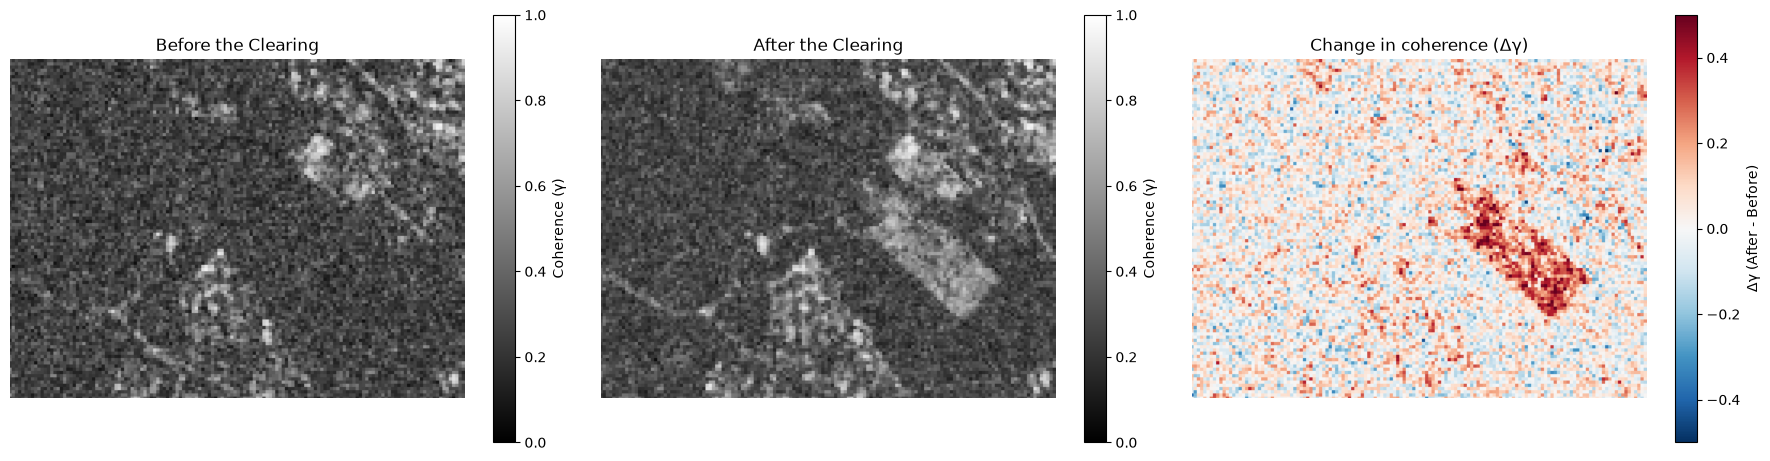

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Pre-Clearing Median
im0 = axes[0].imshow(pre_2d, cmap="gray", vmin=0.0, vmax=1.0, origin="upper", aspect="equal")
fig.colorbar(im0, ax=axes[0], shrink=0.75, label="Coherence (γ)")
axes[0].set_title("Before the Clearing")
axes[0].axis("off")

# Post-Clearing Median
im1 = axes[1].imshow(after_2d, cmap="gray", vmin=0.0, vmax=1.0, origin="upper", aspect="equal")
fig.colorbar(im1, ax=axes[1], shrink=0.75, label="Coherence (γ)")
axes[1].set_title("After the Clearing")
axes[1].axis("off")

# Coherence Change (After - Before)
im2 = axes[2].imshow(diff_2d, cmap="RdBu_r", vmin=-0.5, vmax=0.5, origin="upper", aspect="equal")
fig.colorbar(im2, ax=axes[2], shrink=0.75, label="Δγ (After - Before)")
axes[2].set_title("Change in coherence (Δγ)")
axes[2].axis("off")

plt.tight_layout()
plt.show()

### How to read the results

- **Before Clearing**: We see that most of the values remain dark. This suggests that intact forest covers most of the scene, and that canopy movement in the wind lowers coherence over 12 days. The bright patches may be infrastructure, such as buildings or roads. Check them in the Sentinel-2 browser.
- **After Clearing**: We see a sudden rectangle appearing between the two bright patches, inside the area that was dark forest before.
- **Change**: Features that are present in both periods cancel out and appear white ($\Delta \gamma \approx 0$) because they were rigid both before and after. The cleared area appears red, which means coherence increased.

### True Colour Image

Optical images give a second view of the same change. Their usefulness depends on cloud-free skies, while Sentinel-1 radar works through cloud. That is why both views are useful.

We downloaded two Sentinel-2 true-colour images from the [CDSE Browser](https://browser.dataspace.copernicus.eu/) contained within the interest periods, one from 22 May 2026 before the clearing, and one from 9 August 2026 when the bare soil was completley visible.

The dates are contained within the interest timeframes as optical imagery is limited by cloud cover.

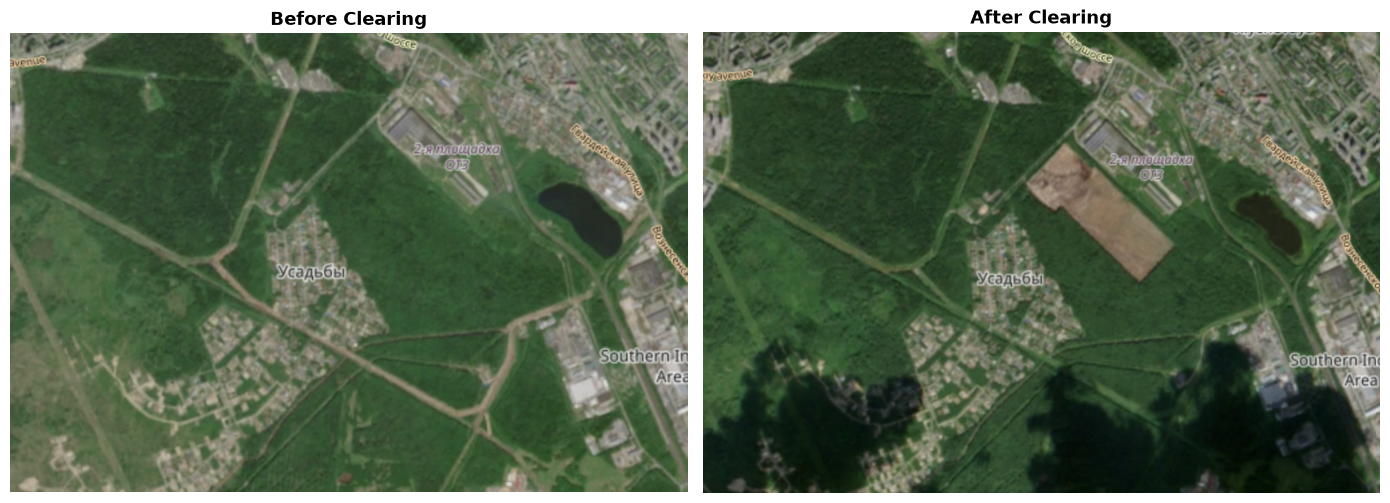

In [27]:
img_before = mpimg.imread("./img/before.png")
img_after = mpimg.imread("./img/after.png")

#  side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(img_before)
axes[0].set_title("Before Clearing", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(img_after)
axes[1].set_title("After Clearing", fontsize=13, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()

## 9️⃣ Takeaways



Radar can show change on the ground when optical images cannot, because it records images day and night, through cloud. In this notebook you used one [APEx algorithm](https://algorithm-catalogue.apex.esa.int/?q=Coherence) to compare two periods over the same area, and saw how the ground changed between them.

Our workflow can be easily reused by:

1. **Choosing the dates of interest**. Use them to query the CDSE burst catalogue for the bursts that cover your area. The choice of burst is made by hand.
2. **Run the same process for both periods**. Identical parameters make the two results comparable.
3. **Compare the median composites, and read the change with its limits**. Side by side, they show where coherence changed. A change in coherence can have causes other than clearing, and one burst covers only part of the area in the report. 


To apply the same workflow to another place or event, we can easily change the area, the dates and the burst. The steps stay the same.

Once you know the pattern, you can use it to act on what the satellites observe, and to recognise what is happening on the ground. Check each algorithm's inputs before you reuse these steps, because other algorithms take different parameters.


## Ready for the next application?

[APEx](https://apex.esa.int/) gives you a catalogue of ESA-validated Earth observation algorithms process directly Sentinel data.<br>

Choose an algorithm, define your area and dates, and the cloud platform returns a result you can map and analyse. @ the [12th CASSINI Hackathon](https://www.cassini.eu/hackathons/), you decide what to recognise and what to act on.

<img src='./img/low_bann.png' style="display: block; margin: 0 auto;">